# Assignment 02: Topic modeling using titles

**Overall purpose:** Answer the five crime-data questions on slide 11 using reproducible topic modeling and evidence-based report analysis. Your section must connect to the shared final report table and the main workstation.

## Shared rules: read before writing code

1. **Claim one assignment.** Add your name and reviewer below, then tell the group. These six notebooks are roles, not six tasks for each person.
2. **Use the shared files.** The original Parquet and shared/reports_base.parquet are read-only inputs. The base adds stable report_id values but does not clean or classify anything.
3. **Keep report_id.** Never recreate IDs after filtering, sorting or resetting an index. Join results using report_id with merge validation. URL is not a unique ID: some URLs repeat.
4. **Use one prepared version.** Member 1 must publish outputs/member_01/reports_prepared.parquet before final modeling. Preserve all source rows and mark exclusions. Everyone records that file's checksum in run_metadata.json. Prototype results on the base are exploratory and must be rerun on the agreed prepared file.
5. **Preserve alignment.** Build each text list and embedding matrix from the same filtered DataFrame in the same order. Never filter/sort text and embeddings separately.
6. **Separate analysis from evidence.** Write short code cells, show readable tables/plots, and explain actual outputs. Do not invent findings, silently fill missing districts, or treat a colored cluster plot as proof of meaningful crime types.
7. **Export to your own folder.** outputs/member_XX holds submissions; figures/member_XX holds readable figures. templates/member_XX contains empty examples and is never a finished submission.
8. **Finish with a peer review.** Everyone contributes their section, interpretation and sample reading. Member 6 coordinates validation; they do not write the entire group project.

**Your name:** Zanele

**Peer reviewer:** ___

**Status:** In progress  

**Prepared input version/checksum:** ______


## Setup and input check

Keep this notebook inside team_notebooks, or beside the shared folder. Copy the project folder when sharing it; the notebook alone does not contain the dataset.

In [61]:
from pathlib import Path
import pandas as pd
import json

In [62]:
project_folder = Path.cwd()
if not (project_folder / "shared").exists():
    project_folder = project_folder.parent

assert (project_folder / "shared/source_manifest.json").exists(), "Open the notebook from the shared project folder."

In [63]:
output_folder = project_folder / "outputs/member_02"
figure_folder = project_folder / "figures/member_02"
output_folder.mkdir(parents=True, exist_ok=True)
figure_folder.mkdir(parents=True, exist_ok=True)

In [64]:
text_columns = ["report_id", "date_posted", "title_en", "description_en", "district", "url"]
reports_base = pd.read_parquet(project_folder / "shared/reports_base.parquet", columns=text_columns)
assert reports_base["report_id"].is_unique
print("Base reports:", len(reports_base))
reports_base[["report_id", "date_posted", "title_en", "district"]].head(3)

Base reports: 5126


,report_id,date_posted,title_en,district
0,BR000000,2026-09-03,Police release wanted photo after shooting in ...,Woltmershausen
1,BR000001,2026-09-03,Burglary in Bar - Police Catch Perpetrators,Ostertor
2,BR000002,2026-09-02,Paint vandalism at high school,Horn


In [65]:
prepared_path = project_folder / "outputs/member_01/reports_prepared.parquet"
if prepared_path.exists():
    prepared_columns = text_columns + ["district_clean", "include_in_analysis", "exclusion_reason"]
    reports = pd.read_parquet(prepared_path, columns=prepared_columns)
    print("Prepared input available. Check its version before modeling.")
else:
    print("Preparation pending: final modeling and group analysis must wait for Member 1.")

Prepared input available. Check its version before modeling.


### Packages

Use the agreed group environment. From the project folder, the setup command is `python -m pip install -r requirements.txt`. Do this only when preparing the modeling environment. The skeleton uses pandas/pyarrow; BERTopic, UMAP and HDBSCAN are not installed in the environment used to check these starter notebooks. No algorithm has been run yet.

## Things to note throughout the project

- Count reports, not confirmed incidents or individual victims. One report can discuss several events or offenses. Treat the unit consistently.
- date_posted is a publication date. The first/last years and boundary months are partial; the source's collection coverage is not established by its date range alone.
- District labels include literal None and potentially different geographic levels. Unknown district reports still matter for citywide totals; district rankings need a consistent reviewed geography.
- Categories such as Theft, Traffic-related, Assault, Burglary, Fraud and Drug-related are candidate names, not predetermined model results. Include an Unknown/Unclear option and a documented non-crime/report-type category where needed.
- A topic is a group of similar reports, not automatically a legal crime category. Several topics can map to one category; mixed topics may need a per-report review.
- Use one primary category per report for the main count tables. If the group later adopts multiple labels, document that totals can exceed the report count and rebuild all comparisons consistently.
- The source includes descriptions of harmful events. Keep relevant evidence brief in outputs, avoid unnecessary identifying details, and use report IDs/source URLs for traceability.
- No API calls, paid services, extra scraping or AI-generated embeddings are needed to start. Optional AI-assisted elderly detection needs a separate agreed method and human verification.


## Purpose and dependencies

You build a topic model using **title_en**. This experiment is central to the group project. Discover groups of words/reports, explain them using real examples, and help turn them into useful crime categories.

**Final input:** Member 1's frozen prepared table. **Method:** TF-IDF + non-negative matrix factorization (NMF). **Model ID:** nmf_titles. **Comparison partner:** Member 3 descriptions. Match their evaluation report IDs and agreed parameter candidates; do not choose a winner in advance.

Your results support Question 1 and supply labels for Questions 2–5. You submit a candidate model; Member 6 coordinates the group's final model/category decision.

### 1. Define the documents and eligible reports

Use only title_en as the model text. Keep the original text and report IDs. Check missing/blank input and shared inclusion flags. Use one common eligible report set for the formal title/description comparison; document additional coverage separately. Never discard missing inputs without recording their assignment_status.

In [66]:
# Step 1: To check title availability and report eligibility

print("Total reports in base dataset:", len(reports_base))
print("Unique report IDs:", reports_base["report_id"].nunique())

# To check which titles are missing or blank
titles = reports_base["title_en"].fillna("").astype(str).str.strip()

missing_title = titles.eq("")

print("Missing or blank titles:", missing_title.sum())
print("Reports with usable titles:", (~missing_title).sum())

# To isplay a small sample for inspection
reports_base[
    ["report_id", "title_en", "district"]
].head(10)

Total reports in base dataset: 5126
Unique report IDs: 5126
Missing or blank titles: 0
Reports with usable titles: 5126


,report_id,title_en,district
0,BR000000,Police release wanted photo after shooting in ...,Woltmershausen
1,BR000001,Burglary in Bar - Police Catch Perpetrators,Ostertor
2,BR000002,Paint vandalism at high school,Horn
3,BR000003,Still waters are deep - and full of e-scooters,Horn
4,BR000004,Bogus water workers steal jewelry,Utbremen
5,BR000005,Incendiary devices hurled at establishment,Alte Neustadt
6,BR000006,Rental vehicles damaged in the Überseestadt,Überseestadt
7,BR000007,Police catch kiosk burglar,Peterswerder
8,BR000008,Public appeal: Money launderer wanted,null
9,BR000009,Man with gunshot wound found,Huckelriede


**Observation:** 
The base dataset contains 5,126 reports with unique report IDs, and all 5,126 have non-empty titles. However, this check uses the base dataset rather than Member 01's prepared dataset. The prepared-data check in Step 5B shows that 5,124 reports are eligible for analysis and 2 are excluded.

**Why it matters**
Traceability and eligibility:Unique report IDs allow model results to be linked back to the original reports. Checking the prepared dataset's inclusion flags is also necessary to ensure that the final analysis follows the agreed eligibility decisions and retains excluded reports with the appropriate status.

**Uncertainty**
Data quality: A non-empty title does not guarantee that it contains enough useful words for topic modelling. Some titles may produce no TF-IDF features, and the initial base-dataset check does not establish which reports are eligible for the final model. These issues are examined using the prepared dataset in Section 5.

### 2. Turn text into a word matrix

Use TfidfVectorizer. Start with English stopwords and one-/two-word phrases; inspect frequent generic police boilerplate and place names. Remove only documented terms that obscure crime meaning. Retain meaningful phrases such as bike theft and traffic accident. Explain TF-IDF simply: common generic words get less weight; informative words help separate reports.

In [67]:
# Later imports for this role:
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.decomposition import NMF

In [68]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Step 2: To prepare title text for TF-IDF

# Keep reports with non-blank titles
title_mask = (
    reports_base["title_en"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
)

title_reports = reports_base.loc[title_mask].copy()

# Create the text list from the same DataFrame
title_texts = title_reports["title_en"].astype(str).tolist()

print("Reports with usable titles:", len(title_texts))
print("Number of documents:", len(title_reports))

title_reports[["report_id", "title_en"]].head(10)


Reports with usable titles: 5126
Number of documents: 5126


,report_id,title_en
0,BR000000,Police release wanted photo after shooting in ...
1,BR000001,Burglary in Bar - Police Catch Perpetrators
2,BR000002,Paint vandalism at high school
3,BR000003,Still waters are deep - and full of e-scooters
4,BR000004,Bogus water workers steal jewelry
5,BR000005,Incendiary devices hurled at establishment
6,BR000006,Rental vehicles damaged in the Überseestadt
7,BR000007,Police catch kiosk burglar
8,BR000008,Public appeal: Money launderer wanted
9,BR000009,Man with gunshot wound found


**Observation:** 
The exploratory TF-IDF matrix contains 5,126 documents, 3,524 text features and 29,657 non-zero values. Each row represents a report title, and each column represents a word or phrase retained by the vectorizer.

**Why it matters**
Text representation:TF-IDF converts report titles into numerical features that NMF can use to identify recurring word patterns. Using individual words and two-word phrases can help capture expressions such as crime types or reporting activities while reducing the influence of common terms.

**Uncertainty**
Comparison with the final input:These figures describe the exploratory matrix built from the base dataset. In Step 5D, the vectorizer is fitted again using the prepared dataset's 5,124 eligible reports, producing 3,523 features. In Step 5G, 24 of those eligible reports are found to have zero TF-IDF features. The two sets of results should not be treated as if they came from the same input.

In [69]:
# Create the TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    max_df=0.90,
    min_df=2
)

# Convert titles into a TF-IDF matrix
tfidf_matrix = tfidf_vectorizer.fit_transform(title_texts)

print("Matrix shape (documents, terms):", tfidf_matrix.shape)
print("Number of unique terms:", len(tfidf_vectorizer.get_feature_names_out()))
print("Number of non-zero values:", tfidf_matrix.nnz)

Matrix shape (documents, terms): (5126, 3524)
Number of unique terms: 3524
Number of non-zero values: 29657


**Observation:** 
The exploratory NMF models were fitted using 6, 8 and 10 topics. Their reconstruction errors decreased as the number of topics increased, from approximately 69.60 with 6 topics to 69.16 with 8 topics and 68.77 with 10 topics. Each model completed quickly in this run.

**Why it matters:** 
Candidate comparison: Testing several topic counts helps show how the grouping of report titles changes as the model becomes more detailed. Reconstruction error provides one measure of how closely a model represents the TF-IDF matrix, but the keywords and representative titles are also needed to assess interpretability.

**Uncertainty**
Model selection:The exploratory results are not the final results because the models in this section use the base dataset. Step 5D refits the candidate models using Member 01's prepared dataset. The 8-topic model is a candidate for further review, not a confirmed winner; the final choice should consider topic interpretability, topic overlap, representative reports and comparison with the description-based model.

### 3. Fit a small set of NMF candidates

Agree a modest candidate set, for example 6, 8 and 10 topics, with your comparison partner. These are starting experiments, not required answers. Set a random seed; record settings and any convergence warnings. Avoid spending the entire project tuning dozens of models. Select an interpretable candidate using the development review sample, and keep held-out review untouched until the settings/category mappings are frozen.

In [70]:
from sklearn.decomposition import NMF
import time

# Step 3: Fit NMF candidate models

topic_candidates = [6, 8, 10]
nmf_models = {}
nmf_results = {}

for n_topics in topic_candidates:
    start_time = time.time()

    model = NMF(
        n_components=n_topics,
        init="nndsvda",
        random_state=42,
        max_iter=400
    )

    document_topic_matrix = model.fit_transform(tfidf_matrix)

    nmf_models[n_topics] = model
    nmf_results[n_topics] = {
        "document_topic_matrix": document_topic_matrix,
        "elapsed_seconds": round(time.time() - start_time, 2),
        "iterations": model.n_iter_,
        "reconstruction_error": model.reconstruction_err_
    }

    print(
        f"Topics: {n_topics} | "
        f"Iterations: {model.n_iter_} | "
        f"Reconstruction error: {model.reconstruction_err_:.2f} | "
        f"Time: {nmf_results[n_topics]['elapsed_seconds']} seconds"
    )

Topics: 6 | Iterations: 35 | Reconstruction error: 69.60 | Time: 0.06 seconds
Topics: 8 | Iterations: 29 | Reconstruction error: 69.16 | Time: 0.03 seconds
Topics: 10 | Iterations: 40 | Reconstruction error: 68.77 | Time: 0.04 seconds


Observation: The NMF models completed in under 0.1 seconds each. Reconstruction error decreased as the number of topics increased: from 69.60 with 6 topics, to 69.16 with 8 topics, and 68.77 with 10 topics.

Why it matters — Comparison: The lower reconstruction error suggests that the 10-topic model represents the TF-IDF data slightly more closely. Comparing different topic counts helps us assess how the model's representation changes as more topics are introduced.

Uncertainty — Meaning: Reconstruction error alone cannot tell us which model produces the most meaningful or interpretable topics. We still need to inspect the keywords and representative report titles for each topic before choosing a model.

### 4. Inspect keywords and real reports

For each topic, display approximately 10 keywords and 3–5 representative report IDs/titles. Add a few randomly selected reports to avoid only inspecting unusually easy examples. Propose a plain category name and explain evidence and mixed cases. Topic numbers have no intrinsic meaning and cannot be compared directly with other models.

In [71]:

# Step 4A: Inspect the top 10 keywords for each topic

# Start by inspecting the 8-topic model
review_n_topics = 8
review_model = nmf_models[review_n_topics]

# Get the words used by the TF-IDF vectorizer
feature_names = tfidf_vectorizer.get_feature_names_out()

# Collect the top 10 keywords for each topic
topic_keyword_rows = []

for topic_id, topic_weights in enumerate(review_model.components_):
    top_indices = topic_weights.argsort()[::-1][:10]
    top_keywords = feature_names[top_indices]

    topic_keyword_rows.append({
        "topic_id": topic_id,
        "keywords": "; ".join(top_keywords)
    })

# Display the results
keywords_df = pd.DataFrame(topic_keyword_rows)
display(keywords_df)


,topic_id,keywords
0,0,injured; seriously injured; seriously; knife; ...
1,1,police; bremen; bremen police; officers; polic...
2,2,station; gas; gas station; robbed; station rob...
3,3,accident; traffic; traffic accident; injured t...
4,4,burglar; caught; apprehended; burglar caught; ...
5,5,year; old; year old; missing; old injured; old...
6,6,robbery; witnesses; sought; witnesses sought; ...
7,7,operation; police operation; police; triggers;...


The exploratory eight-topic NMF model produces groups of related words and phrases that suggest recurring patterns in the crime-report titles. The keywords include traffic-accident terms, police-related wording, references to people described by age, gas-station robberies, burglars being caught, serious injuries and knife incidents, witness appeals, and police operations.

Some groups appear more specific than others. For example, the gas-station robbery and burglar-apprehension keywords suggest relatively focused themes, while the age-related terms may combine reports about different incidents. The police-related topics also contain overlapping terminology, so the keywords alone do not establish that the topics represent distinct crime categories.

This exploratory keyword inspection provides an initial view of the themes that NMF can identify in report titles. The final candidate models are fitted separately using Member 01's prepared dataset in Step 5. Their keywords and representative titles are examined there, and the selected eight-topic model is evaluated further in Section 6. The topic labels remain provisional until the results have been compared with the description-based model and reviewed by a peer.

### 5. Produce per-report assignments

Use model_id=nmf_titles. Output one row for every base report_id, including excluded and missing-text reports. Use assignment_status from the contract. NMF document-topic weights can identify a strongest topic, but they are not calibrated probabilities. Reports with zero usable word features must remain unassigned; do not accidentally assign them all to Topic 0 through argmax.

In [72]:
# Step 5A: Check Member 01's prepared dataset

from pathlib import Path
import hashlib
import pandas as pd

# The notebook is inside team_notebooks,
# so go up one level to the main project folder.
project_root = Path.cwd().parent

prepared_file = (
    project_root / "outputs" / "member_01" / "reports_prepared.parquet"
)

print("Project folder:", project_root)
print("Prepared file found:", prepared_file.exists())

if prepared_file.exists():
    # Calculate the SHA-256 checksum
    sha256 = hashlib.sha256()

    with open(prepared_file, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha256.update(chunk)

    prepared_checksum = sha256.hexdigest()

    # Read the prepared dataset
    prepared_reports = pd.read_parquet(prepared_file)

    print("Number of rows:", len(prepared_reports))
    print("Number of columns:", len(prepared_reports.columns))
    print("Column names:", prepared_reports.columns.tolist())
    print("SHA-256 checksum:", prepared_checksum)
else:
    print("File not found. We need to check the folder structure.")

Project folder: /Users/zaangwenya/Documents/bremen-crime-data-analytics-main
Prepared file found: True
Number of rows: 5126
Number of columns: 11
Column names: ['report_id', 'date_posted', 'title_en', 'description_en', 'district', 'desc_en_embeddings768', 'title_en_embeddings768', 'url', 'district_clean', 'include_in_analysis', 'exclusion_reason']
SHA-256 checksum: bf64238b7f929551cf20dadcdd314fa8bf17efe2cd7eab6174fd44dab1a1c139


Member 01's prepared dataset was successfully located in the project folder. It contained 5,126 rows and 11 columns, including `report_id`, `title_en`, `description_en`, `include_in_analysis`, and `exclusion_reason`. The dataset also contained precomputed title and description embeddings. The SHA-256 checksum was `bf64238b7f929551cf20dadcdd314fa8bf17efe2cd7eab6174fd44dab1a1c139`.

This matters because the prepared dataset is the agreed input for the topic-modelling analysis. Recording its checksum helps verify that the same dataset version is used when reproducing the results. The available report IDs and inclusion flags also allow reports to be tracked throughout the analysis.

What remains uncertain is whether the report titles, descriptions, translations, and exclusion decisions accurately represent the original reports. The successful file check and checksum confirm the dataset's availability and identity, but do not establish the accuracy or quality of its contents.

In [73]:

# Step 5B: Prepare the output folder and check eligibility

output_dir = project_root / "outputs" / "member_02"
output_dir.mkdir(parents=True, exist_ok=True)

print("Output folder:", output_dir)
print("Output folder exists:", output_dir.exists())

# Check Member 01's inclusion and exclusion decisions
print("\nEligibility counts:")
print(prepared_reports["include_in_analysis"].value_counts(dropna=False))

print("\nExclusion reasons:")
print(prepared_reports["exclusion_reason"].value_counts(dropna=False))

Output folder: /Users/zaangwenya/Documents/bremen-crime-data-analytics-main/outputs/member_02
Output folder exists: True

Eligibility counts:
include_in_analysis
True     5124
False       2
Name: count, dtype: int64

Exclusion reasons:
exclusion_reason
                                                  5124
Duplicate of retained matching report BR001568       1
Duplicate of retained matching report BR002113       1
Name: count, dtype: int64


The output folder for Member 02(Zanele) exists, so the location for saving my assignment results is available. The prepared dataset contains 5,126 reports in total. Of these, 5,124 reports (`include_in_analysis = True`) are eligible for analysis, while 2 reports (`include_in_analysis = False`) are excluded. Both exclusions have documented reasons: one report is a duplicate of retained report `BR001568`, and the other is a duplicate of retained report `BR002113`. The remaining 5,124 reports have no recorded exclusion reason.

Checking eligibility before modelling helps ensure that the analysis follows the dataset's inclusion decisions and avoids counting duplicate reports as separate observations. Keeping the two excluded reports identifiable also supports traceability and reproducibility. These reports should remain in the final assignment output with the status `excluded`, rather than being silently deleted.

This check confirms that the exclusion flags and reasons are recorded in the dataset, but it does not independently verify whether the two reports are genuine duplicates. It also does not establish whether all eligible reports contain useful text for topic modelling; that must be checked separately before assigning topics.

In [74]:

# Step 5C: Prepare eligible reports for final modeling

# Keep only reports Member 01 marked for analysis
eligible_reports = prepared_reports.loc[
    prepared_reports["include_in_analysis"].eq(True)
].copy()

# Check for missing or blank titles among eligible reports
title_mask = (
    eligible_reports["title_en"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
)

model_reports = eligible_reports.loc[title_mask].copy()

print("Total prepared reports:", len(prepared_reports))
print("Eligible reports:", len(eligible_reports))
print("Excluded reports:", len(prepared_reports) - len(eligible_reports))
print("Eligible reports with usable titles:", len(model_reports))
print("Eligible reports with missing or blank titles:", int((~title_mask).sum()))
print("Unique report IDs in modeling dataset:", model_reports["report_id"].nunique())


Total prepared reports: 5126
Eligible reports: 5124
Excluded reports: 2
Eligible reports with usable titles: 5124
Eligible reports with missing or blank titles: 0
Unique report IDs in modeling dataset: 5124


The prepared dataset contains 5,126 reports, of which 5,124 are eligible for analysis and 2 are excluded. All 5,124 eligible reports have usable titles, with no missing or blank titles. The modeling dataset also contains 5,124 unique report IDs, meaning there are no duplicate report IDs among the eligible reports.

Topic modelling relies on text to identify patterns across reports. Confirming that all eligible reports have usable titles means that no eligible report needs to be excluded because its title is missing or blank. Checking the uniqueness of report IDs also helps ensure that each report can be tracked correctly when topic assignments are created and saved.

Although all eligible reports have non-empty titles and unique IDs, this does not guarantee that every title contains enough meaningful information for the model to analyse. Some titles may contain words that are removed during text preprocessing or may produce no features in the TF-IDF representation. These cases need to be checked during the modelling process.

In [75]:

# Step 5D: Fit candidate models on Member 01's prepared data

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF
import time

# Use the prepared titles from Step 5C
final_texts = model_reports["title_en"].astype(str).tolist()

# Convert titles into numerical TF-IDF features
final_vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    max_df=0.90,
    min_df=2
)

final_tfidf_matrix = final_vectorizer.fit_transform(final_texts)

# Test models with 6, 8, and 10 topics
final_topic_candidates = [6, 8, 10]
final_nmf_models = {}
final_nmf_results = {}

for n_topics in final_topic_candidates:
    start_time = time.time()

    model = NMF(
        n_components=n_topics,
        init="nndsvda",
        random_state=42,
        max_iter=400
    )

    document_topic_matrix = model.fit_transform(final_tfidf_matrix)

    final_nmf_models[n_topics] = model
    final_nmf_results[n_topics] = {
        "document_topic_matrix": document_topic_matrix,
        "elapsed_seconds": round(time.time() - start_time, 2),
        "iterations": model.n_iter_,
        "reconstruction_error": model.reconstruction_err_
    }

    print(
        f"Topics: {n_topics} | "
        f"Iterations: {model.n_iter_} | "
        f"Reconstruction error: {model.reconstruction_err_:.2f} | "
        f"Time: {final_nmf_results[n_topics]['elapsed_seconds']} seconds"
    )

print("\nFinal TF-IDF matrix shape:", final_tfidf_matrix.shape)
print("Prepared reports modeled:", len(final_texts))


Topics: 6 | Iterations: 34 | Reconstruction error: 69.59 | Time: 0.03 seconds
Topics: 8 | Iterations: 32 | Reconstruction error: 69.15 | Time: 0.03 seconds
Topics: 10 | Iterations: 41 | Reconstruction error: 68.76 | Time: 0.04 seconds

Final TF-IDF matrix shape: (5124, 3523)
Prepared reports modeled: 5124


I fitted three Non-negative Matrix Factorization (NMF) models using 6, 8, and 10 topics. The models required 34, 32, and 41 iterations, respectively. Their reconstruction errors were 69.59 for 6 topics, 69.15 for 8 topics, and 68.76 for 10 topics. The TF-IDF matrix had 5,124 rows and 3,523 columns, representing 5,124 eligible reports and 3,523 text features. All 5,124 eligible reports were included in the modelling dataset.

Testing different numbers of topics helps assess how the model groups reports at different levels of detail. The reconstruction error decreased as the number of topics increased, meaning the 10-topic model represented the TF-IDF matrix slightly better according to this measure. The TF-IDF matrix also confirms that the model had text features available for analysis across the eligible reports.

A lower reconstruction error does not automatically mean that a model produces more meaningful or interpretable crime categories. The 10-topic model may create more specific topics, but some topics could overlap or be difficult to label. The candidate models therefore need to be compared by examining their keywords and representative report titles, rather than choosing a model based on reconstruction error alone.

In [76]:

# Step 5E: Inspect the top keywords for each candidate model

feature_names = final_vectorizer.get_feature_names_out()

for n_topics, model in final_nmf_models.items():
    print(f"\n{'=' * 60}")
    print(f"MODEL WITH {n_topics} TOPICS")
    print('=' * 60)

    for topic_id, topic_weights in enumerate(model.components_):
        top_indices = topic_weights.argsort()[-10:][::-1]
        top_words = [feature_names[i] for i in top_indices]

        print(f"\nTopic {topic_id}: {', '.join(top_words)}")



MODEL WITH 6 TOPICS

Topic 0: accident, traffic, traffic accident, injured traffic, dies, dies traffic, driver, car, a1, fatal

Topic 1: police, bremen, operation, police operation, bremen police, officers, police officers, arrest, police arrest, accompanies

Topic 2: year, old, year old, missing, old injured, robbed, old attacked, attacked, old robbed, 20

Topic 3: station, gas, gas station, robbery, robbed, station robbed, witnesses, appeal, witness, sought

Topic 4: burglar, caught, apprehended, burglar caught, burglar apprehended, car, car burglar, robber, suspected, thief

Topic 5: injured, seriously injured, seriously, knife, injured knife, man, cyclist, cyclist seriously, pedestrian, injured traffic

MODEL WITH 8 TOPICS

Topic 0: accident, traffic, traffic accident, injured traffic, dies, dies traffic, driver, car, a1, fatal

Topic 1: police, bremen, bremen police, officers, police officers, arrest, police accompanies, accompanies, police arrest, apprehends

Topic 2: year, old,



The keywords show several recurring themes across all three NMF models. Topic 0 consistently contains terms related to traffic accidents, such as “accident,” “traffic,” “injured,” and “driver.” Another topic consistently contains police-related terms, including “police,” “Bremen,” and “officers.” Other recurring themes include reports involving older or missing people, gas-station robberies, burglars being caught, serious injuries, and witness appeals.

The 6-topic model combines some themes. For example, its Topic 3 includes both gas-station robbery terms and witness-appeal terms. In the 8-topic model, these terms are separated into Topic 3, focused on gas-station robberies, and Topic 6, focused on witness appeals after robbery. The 10-topic model further separates witness appeals into Topics 6 and 8, while Topic 9 contains terms associated with people or places being robbed. Some overlap remains between topics, particularly for police-related reports and reports involving injuries or robberies.

Comparing the keywords helps determine whether increasing the number of topics produces more distinct and interpretable themes. The 8-topic model separates gas-station robberies from witness appeals while retaining the recurring themes found in the other models. The 10-topic model introduces additional distinctions, but its topics also show overlap in terms such as “witness,” “appeal,” and “robbery.” These observations support examining the 8-topic model further before finalising the topic selection.

Keywords alone do not show whether every report assigned to a topic fits its apparent theme. Some topics contain broad or overlapping terms, and the age-related topic may combine different types of incidents simply because their titles mention a person's age. The proposed topic labels therefore need to be checked against representative report titles and compared with the description-based model before concluding that the topics represent reliable crime categories.

In [77]:

# Step 5F: Inspect representative titles actually assigned to each topic

import numpy as np

selected_n_topics = 8
document_topic_matrix = final_nmf_results[
    selected_n_topics
]["document_topic_matrix"]

# Keep report IDs and title rows aligned with the TF-IDF matrix.
model_report_ids = model_reports["report_id"].to_numpy()
model_titles = model_reports["title_en"].to_numpy()

# Exclude reports that have no usable TF-IDF features.
nonzero_mask = np.asarray(
    final_tfidf_matrix.getnnz(axis=1)
).ravel() > 0

# Assign each usable report to its highest-scoring topic.
assigned_topic_ids = document_topic_matrix.argmax(axis=1)

for topic_id in range(selected_n_topics):
    print(f"\n{'=' * 60}")
    print(f"TOPIC {topic_id} — REPRESENTATIVE ASSIGNED TITLES")
    print("=" * 60)

    # Only include usable reports assigned to this topic.
    candidate_indices = np.where(
        nonzero_mask & (assigned_topic_ids == topic_id)
    )[0]

    # Rank those reports by their score for this topic.
    ranked_indices = candidate_indices[
        np.argsort(
            document_topic_matrix[candidate_indices, topic_id]
        )[::-1]
    ][:5]

    for idx in ranked_indices:
        print(
            f"Score: "
            f"{document_topic_matrix[idx, topic_id]:.6f} | "
            f"Report ID: {model_report_ids[idx]} | "
            f"Title: {model_titles[idx]}"
        )


TOPIC 0 — REPRESENTATIVE ASSIGNED TITLES
Score: 0.223932 | Report ID: BR002793 | Title: Traffic accident with four involved parties
Score: 0.223932 | Report ID: BR004452 | Title: Traffic accident in Strom
Score: 0.177107 | Report ID: BR002874 | Title: Several injured in traffic accident
Score: 0.177107 | Report ID: BR004360 | Title: Injured after traffic accident
Score: 0.176888 | Report ID: BR004571 | Title: Several violations after traffic accident

TOPIC 1 — REPRESENTATIVE ASSIGNED TITLES
Score: 0.283326 | Report ID: BR000976 | Title: Wee-woo wee-woo, the police aren't here!
Score: 0.240836 | Report ID: BR005061 | Title: Application process starts at the Bremen Police
Score: 0.195287 | Report ID: BR003989 | Title: Bremen Police accompanies Nordderby
Score: 0.194205 | Report ID: BR001371 | Title: Police arrests fake police officers
Score: 0.183095 | Report ID: BR004051 | Title: Bremen Police prepare for the weekend

TOPIC 2 — REPRESENTATIVE ASSIGNED TITLES
Score: 0.226995 | Report I

I examined five representative report titles for each of the eight topics in the selected NMF model. Topic 0 contains traffic-accident reports, including titles about multiple parties being involved and people being injured. Topic 1 contains a mixture of police-related reports, such as recruitment, police activities, and arrests involving fake police officers. Topic 2 includes reports involving people of different ages, including attacks, missing-person reports, and fraud or robbery. Topic 3 is strongly associated with gas-station robberies, while Topic 4 contains reports about burglars being caught. Topic 5 includes reports about serious injuries and knife incidents, as well as seriously injured cyclists. Topic 6 focuses on appeals for witnesses following robberies. Topic 7 contains reports about different police operations, including incidents involving rat poison, nitrous oxide, and other situations requiring police attention.

Inspecting representative titles helps determine whether the keywords correspond to understandable themes in the actual reports. Several topics show a clear pattern, particularly traffic accidents (Topic 0), gas-station robberies (Topic 3), burglars being caught (Topic 4), and witness appeals (Topic 6). However, Topics 1, 2, and 5 cover more varied incidents, so their labels should be broader and interpreted cautiously. This review provides additional evidence for evaluating whether the eight-topic model is useful and interpretable.

The representative titles are examples, not a complete review of every report assigned to each topic. Some titles are repeated or very similar, which may indicate recurring reporting patterns but does not establish that the underlying incidents are identical. The scores indicate how strongly the model associates a title with a topic; they should not be interpreted as calibrated probabilities or proof that a report belongs exclusively to that category. Reviewing more reports and comparing these results with the description-based model would help assess the topics' consistency and limitations.

In [78]:

# Step 5G: Check model coverage and assignment scores

import numpy as np

# A report needs at least one nonzero TF-IDF feature to be modeled
nonzero_mask = np.asarray(
    final_tfidf_matrix.getnnz(axis=1)
).ravel() > 0

# Get each report's highest topic score in the 8-topic model
document_topic_matrix = final_nmf_results[8]["document_topic_matrix"]
max_topic_scores = document_topic_matrix.max(axis=1)

print("Reports in modeling dataset:", len(model_reports))
print("Reports with usable TF-IDF features:", int(nonzero_mask.sum()))
print("Reports with zero TF-IDF features:", int((~nonzero_mask).sum()))
print("Reports with a topic score above zero:",
      int((max_topic_scores > 0).sum()))
print("Lowest positive maximum topic score:",
      round(float(max_topic_scores[max_topic_scores > 0].min()), 4)
      if (max_topic_scores > 0).any() else "None")
print("Median maximum topic score:",
      round(float(np.median(max_topic_scores)), 4))
print("Highest maximum topic score:",
      round(float(max_topic_scores.max()), 4))

Reports in modeling dataset: 5124
Reports with usable TF-IDF features: 5100
Reports with zero TF-IDF features: 24
Reports with a topic score above zero: 5100
Lowest positive maximum topic score: 0.0
Median maximum topic score: 0.0449
Highest maximum topic score: 0.3905


The modeling dataset contains 5,124 reports. Of these, 5,100 have usable TF-IDF features, while 24 have zero TF-IDF features. All 5,100 reports with usable features have a topic score above zero. The median maximum topic score is 0.0449, and the highest maximum topic score is 0.3905. The lowest positive maximum topic score is displayed as 0.0, likely because the value is very small and has been rounded for display.

TF-IDF features represent the words and phrases the model can use to identify patterns in report titles. Reports with zero TF-IDF features cannot be meaningfully assigned to a topic using the model's topic scores, so they should not receive a topic assignment based on an arbitrary maximum. Identifying these 24 reports helps preserve accurate assignment statuses and ensures that the final output distinguishes reports that were assigned to a topic from those that could not be modelled.

The output does not explain exactly why each of the 24 reports produced zero TF-IDF features. Their titles may contain words removed during preprocessing or terms that do not meet the vectorizer's vocabulary requirements. Also, the maximum topic scores show the strength of the model's representation, not the probability that a topic is correct. The lowest positive score should be examined with greater numerical precision if its exact value is important.

In [79]:

# Step 5H: Create assignments for all prepared reports

import numpy as np
import pandas as pd

selected_n_topics = 8
document_topic_matrix = final_nmf_results[
    selected_n_topics
]["document_topic_matrix"]

# Start with every original report ID
final_assignments = prepared_reports[["report_id"]].copy()
final_assignments["model_id"] = "nmf_titles"
final_assignments["topic_id"] = pd.NA
final_assignments["assignment_status"] = "unassigned"

# Mark reports excluded by Member 01
excluded_mask = ~prepared_reports["include_in_analysis"].eq(True)
final_assignments.loc[
    excluded_mask, "assignment_status"
] = "excluded"

# Find eligible reports with missing or blank titles
eligible_mask = prepared_reports["include_in_analysis"].eq(True)
title_missing_mask = (
    prepared_reports["title_en"]
    .fillna("")
    .astype(str)
    .str.strip()
    .eq("")
)
missing_text_mask = eligible_mask & title_missing_mask

final_assignments.loc[
    missing_text_mask, "assignment_status"
] = "missing_text"

# Assign topics only to reports with nonzero TF-IDF features
# model_reports and the TF-IDF matrix have matching row order
nonzero_mask = np.asarray(
    final_tfidf_matrix.getnnz(axis=1)
).ravel() > 0

usable_report_ids = model_reports.loc[
    nonzero_mask, "report_id"
].to_numpy()

usable_topic_ids = document_topic_matrix[
    nonzero_mask
].argmax(axis=1)

topic_lookup = pd.DataFrame({
    "report_id": usable_report_ids,
    "topic_id": usable_topic_ids
})

topic_map = topic_lookup.set_index("report_id")["topic_id"]
usable_assignment_mask = final_assignments["report_id"].isin(
    usable_report_ids
)

final_assignments.loc[
    usable_assignment_mask, "topic_id"
] = final_assignments.loc[
    usable_assignment_mask, "report_id"
].map(topic_map)

final_assignments.loc[
    usable_assignment_mask, "assignment_status"
] = "assigned"

# Check coverage and status counts
print("Total assignment rows:", len(final_assignments))
print("Unique report IDs:", final_assignments["report_id"].nunique())
print("\nAssignment status counts:")
print(final_assignments["assignment_status"].value_counts(dropna=False))
print("\nTopic counts among assigned reports:")
print(
    final_assignments.loc[
        final_assignments["assignment_status"].eq("assigned"),
        "topic_id"
    ].value_counts().sort_index()
)


Total assignment rows: 5126
Unique report IDs: 5126

Assignment status counts:
assignment_status
assigned      5100
unassigned      24
excluded         2
Name: count, dtype: int64

Topic counts among assigned reports:
topic_id
0     418
1    1965
2     326
3     378
4     589
5     382
6     581
7     461
Name: count, dtype: int64


The final assignment table contains 5,126 rows, with 5,126 unique report IDs, confirming that every report in the prepared dataset is represented exactly once. Of these, 5,100 reports are assigned to a topic, 24 are marked as `unassigned` because they have no usable TF-IDF features, and 2 are marked as `excluded` because they were excluded from the analysis during preparation. No reports have the status `missing_text`, because all eligible reports had non-empty titles.

Among the 5,100 assigned reports, Topic 1 has the largest number of assignments, with 1,965 reports. Topic 4 has 589 reports, Topic 6 has 581, Topic 7 has 461, Topic 0 has 418, Topic 5 has 382, Topic 3 has 378, and Topic 2 has the smallest number, with 326 reports.

Preserving all 5,126 report IDs makes the assignments traceable to the original prepared dataset. Using separate statuses ensures that excluded reports and reports that could not be represented by TF-IDF features are not incorrectly assigned to a topic. The topic counts also show how reports are distributed across the eight topics and highlight that Topic 1 is substantially larger than the others.

The assignment counts alone do not establish whether each report has been placed in the most appropriate topic. Topic 1's large size may reflect a broad range of police-related titles, so its internal consistency deserves further review. The model assigns each usable report to its highest-scoring topic, but this does not guarantee that the assignment is correct. Reviewing more titles and comparing the results with the description-based model would help assess the quality of these assignments.

In [80]:

# Step 5I: Generate and save final Assignment 02 outputs

from pathlib import Path
from datetime import datetime
import hashlib
import json
import platform
import time
import sklearn
import pandas as pd
import numpy as np

# --------------------------------------------------
# 1. Set paths and selected model
# --------------------------------------------------

output_dir = project_root / "outputs" / "member_02"
output_dir.mkdir(parents=True, exist_ok=True)

figures_dir = project_root / "figures" / "member_02"
figures_dir.mkdir(parents=True, exist_ok=True)

model_id = "nmf_titles"
selected_n_topics = 8
selected_model = final_nmf_models[selected_n_topics]
document_topic_matrix = final_nmf_results[
    selected_n_topics
]["document_topic_matrix"]
feature_names = final_vectorizer.get_feature_names_out()

# --------------------------------------------------
# 2. Save report-level assignments
# --------------------------------------------------

assignments_path = output_dir / "nmf_titles_assignments.csv"

assignments_to_save = final_assignments[
    ["report_id", "model_id", "topic_id", "assignment_status"]
].copy()

assignments_to_save.to_csv(assignments_path, index=False)

# --------------------------------------------------
# 3. Create topic descriptions
# --------------------------------------------------

topic_labels = {
    0: "Traffic accidents",
    1: "Police activity and announcements",
    2: "Reports involving age-related references",
    3: "Gas-station robberies",
    4: "Burglars caught or apprehended",
    5: "Serious injuries and knife incidents",
    6: "Witness appeals after robbery",
    7: "Police operations"
}

topic_notes = {
    0: "Keywords and sampled titles mainly describe traffic accidents. May combine different accident circumstances.",
    1: "Includes police announcements, recruitment, arrests and other police-related reports; category is broad.",
    2: "Mixed topic involving age references alongside missing-person, attack, fraud and robbery reports. Interpret cautiously.",
    3: "Strong concentration of gas-station robbery titles.",
    4: "Strong concentration of titles describing burglars being caught or apprehended.",
    5: "Combines serious injuries, knife incidents and injured road users; not a single incident type.",
    6: "Strong concentration of appeals seeking witnesses after robberies.",
    7: "Police-operation titles with varied reasons and circumstances."
}

topic_rows = []
for topic_id, topic_weights in enumerate(selected_model.components_):
    top_indices = topic_weights.argsort()[-10:][::-1]
    keywords = ", ".join(feature_names[top_indices])

    n_reports = int(
        (
            final_assignments["assignment_status"].eq("assigned")
            & final_assignments["topic_id"].eq(topic_id)
        ).sum()
    )

    topic_rows.append({
        "model_id": model_id,
        "topic_id": topic_id,
        "keywords": keywords,
        "n_reports": n_reports,
        "proposed_category": topic_labels[topic_id],
        "notes": topic_notes[topic_id]
    })

topics_df = pd.DataFrame(topic_rows)
topics_path = output_dir / "nmf_titles_topics.csv"
topics_df.to_csv(topics_path, index=False)

# --------------------------------------------------
# 4. Select five representative assigned reports per topic
# --------------------------------------------------

sample_rows = []

# Match each modeling row to its report ID
model_report_ids = model_reports["report_id"].to_numpy()

for topic_id in range(selected_n_topics):
    topic_scores = document_topic_matrix[:, topic_id]

    for idx in np.argsort(topic_scores)[::-1]:
        report_id = model_report_ids[idx]

        # Samples must come from reports assigned to this topic
        match = final_assignments.loc[
            final_assignments["report_id"].eq(report_id)
            & final_assignments["assignment_status"].eq("assigned")
            & final_assignments["topic_id"].eq(topic_id)
        ]

        if not match.empty:
            sample_rows.append({
                "model_id": model_id,
                "topic_id": topic_id,
                "report_id": report_id,
                "selection_reason": (
                    "Among the highest-scoring reports assigned to this topic"
                )
            })

        if sum(
            row["topic_id"] == topic_id for row in sample_rows
        ) >= 5:
            break

samples_df = pd.DataFrame(
    sample_rows,
    columns=[
        "model_id", "topic_id", "report_id", "selection_reason"
    ]
)

samples_path = output_dir / "nmf_titles_samples.csv"
samples_df.to_csv(samples_path, index=False)

# --------------------------------------------------
# 5. Create run summary
# --------------------------------------------------

status_counts = final_assignments["assignment_status"].value_counts()

def status_count(status):
    return int(status_counts.get(status, 0))

run_parameters = {
    "vectorizer": "TfidfVectorizer",
    "stop_words": "english",
    "ngram_range": [1, 2],
    "max_df": 0.90,
    "min_df": 2,
    "nmf_init": "nndsvda",
    "random_state": 42,
    "max_iter": 400,
    "topic_candidates": [6, 8, 10],
    "selected_n_topics": selected_n_topics,
    "assignment_rule": "Highest NMF topic score for reports with nonzero TF-IDF features",
    "zero_feature_rule": "Do not assign a topic; mark as unassigned"
}

run_df = pd.DataFrame([{
    "model_id": model_id,
    "n_topics": selected_n_topics,
    "assigned_reports": status_count("assigned"),
    "unassigned_reports": status_count("unassigned"),
    "excluded_reports": status_count("excluded"),
    "missing_text_reports": status_count("missing_text"),
    "invalid_embedding_reports": status_count("invalid_embedding"),
    "elapsed_seconds": final_nmf_results[selected_n_topics]["elapsed_seconds"],
    "parameters": json.dumps(run_parameters)
}])

run_path = output_dir / "nmf_titles_run.csv"
run_df.to_csv(run_path, index=False)

# --------------------------------------------------
# 6. Create run metadata
# --------------------------------------------------

prepared_file = (
    project_root / "outputs" / "member_01" / "reports_prepared.parquet"
)

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

metadata = {
    "name": "Assignment 02: Topic modeling using titles",
    "model_id": model_id,
    "input_files": {
        "prepared_reports": str(
            Path("outputs") / "member_01" / "reports_prepared.parquet"
        ),
        "sha256": sha256_file(prepared_file)
    },
    "method": "TF-IDF + Non-negative Matrix Factorization (NMF)",
    "selected_n_topics": selected_n_topics,
    "method_settings": run_parameters,
    "package_versions": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
        "numpy": np.__version__
    },
    "run_date": datetime.now().astimezone().isoformat(timespec="seconds"),
    "record_counts": {
        "prepared_reports": int(len(prepared_reports)),
        "eligible_reports": int(
            prepared_reports["include_in_analysis"].eq(True).sum()
        ),
        "usable_tfidf_reports": int(nonzero_mask.sum()),
        "unique_assignment_report_ids": int(
            final_assignments["report_id"].nunique()
        )
    },
    "assignment_status_counts": {
        status: int(count)
        for status, count in status_counts.items()
    },
    "candidate_model_results": {
        str(k): {
            "iterations": int(v["iterations"]),
            "reconstruction_error": float(v["reconstruction_error"]),
            "elapsed_seconds": float(v["elapsed_seconds"])
        }
        for k, v in final_nmf_results.items()
    },
    "notes": [
        "Topic IDs are model-derived clusters, not verified crime categories.",
        "NMF scores are not calibrated probabilities.",
        "Reports with zero TF-IDF features are unassigned.",
        "Two excluded reports are retained in the assignment output."
    ]
}

metadata_path = output_dir / "run_metadata.json"
with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2, ensure_ascii=False)

# --------------------------------------------------
# 7. Create handover notes
# --------------------------------------------------

handover_text = f"""# Assignment 02: Topic modeling using titles

## Model
- Model ID: `{model_id}`
- Method: TF-IDF + NMF
- Selected topic count: {selected_n_topics}
- Input: `outputs/member_01/reports_prepared.parquet`
- Input SHA-256: `{metadata["input_files"]["sha256"]}`

## Method settings
- TF-IDF stop words: English
- N-gram range: (1, 2)
- Maximum document frequency: 0.90
- Minimum document frequency: 2
- NMF initialization: `nndsvda`
- Random state: 42
- Maximum iterations: 400

## Topic interpretation
Topic labels in `nmf_titles_topics.csv` are proposed interpretations based on top keywords and representative report titles. They are not verified crime classifications.

Topics 0, 3, 4 and 6 showed relatively consistent patterns in the inspected examples. Topics 1, 2 and 5 combine different report types and should be interpreted cautiously. Topic 7 captures police-operation reports with varied circumstances.

## Assignment coverage
- Prepared reports: {len(prepared_reports)}
- Assigned: {status_count("assigned")}
- Unassigned due to zero TF-IDF features: {status_count("unassigned")}
- Excluded: {status_count("excluded")}
- Missing text: {status_count("missing_text")}
- Invalid embedding: {status_count("invalid_embedding")}

## Limitations
- NMF groups titles by word patterns; it does not establish what happened in a report.
- Topic scores are not calibrated probabilities.
- A report is assigned to its highest-scoring topic only if its TF-IDF row has nonzero features.
- Reconstruction error alone does not establish topic quality.
- The proposed categories require reviewer validation.

## Peer review and outstanding questions
- Peer reviewer: Member 06.
- Compare these topics with Member 03's description-based model.
- Review mixed topics and confirm whether the proposed labels are appropriate.
- Record reviewer feedback and any changes here before final submission.

## Output inventory
- `nmf_titles_assignments.csv`
- `nmf_titles_topics.csv`
- `nmf_titles_samples.csv`
- `nmf_titles_run.csv`
- `run_metadata.json`
- `handover.md`
"""

handover_path = output_dir / "handover.md"
handover_path.write_text(handover_text, encoding="utf-8")

# --------------------------------------------------
# 8. Verify outputs
# --------------------------------------------------

print("Files saved:")
for path in [
    assignments_path, topics_path, samples_path,
    run_path, metadata_path, handover_path
]:
    print(f"- {path.relative_to(project_root)} | exists: {path.exists()}")

print("\nAssignment status counts:")
print(final_assignments["assignment_status"].value_counts())

print("\nTopic table:")
print(topics_df[["topic_id", "proposed_category", "n_reports"]])

print("\nRepresentative samples:", len(samples_df))
print("Input SHA-256:", metadata["input_files"]["sha256"])


Files saved:
- outputs/member_02/nmf_titles_assignments.csv | exists: True
- outputs/member_02/nmf_titles_topics.csv | exists: True
- outputs/member_02/nmf_titles_samples.csv | exists: True
- outputs/member_02/nmf_titles_run.csv | exists: True
- outputs/member_02/run_metadata.json | exists: True
- outputs/member_02/handover.md | exists: True

Assignment status counts:
assignment_status
assigned      5100
unassigned      24
excluded         2
Name: count, dtype: int64

Topic table:
   topic_id                         proposed_category  n_reports
0         0                         Traffic accidents        418
1         1         Police activity and announcements       1965
2         2  Reports involving age-related references        326
3         3                     Gas-station robberies        378
4         4            Burglars caught or apprehended        589
5         5      Serious injuries and knife incidents        382
6         6             Witness appeals after robbery      

All six expected deliverable files were saved successfully in `outputs/member_02/`: `nmf_titles_assignments.csv`, `nmf_titles_topics.csv`, `nmf_titles_samples.csv`, `nmf_titles_run.csv`, `run_metadata.json`, and `handover.md`. The assignment table contains 5,100 assigned reports, 24 unassigned reports, and 2 excluded reports. The topic table contains eight topics with proposed categories and report counts. Topic 1, “Police activity and announcements,” has the most assignments, with 1,965 reports, while Topic 2, “Reports involving age-related references,” has the fewest, with 326 reports. The representative-sample file contains 40 examples. The input SHA-256 checksum is recorded as `bf64238b7f929551cf20dadcdd314fa8bf17efe2cd7eab6174fd44dab1a1c139`.

Saving these files creates a structured and reproducible record of the analysis. The assignments file links each report to its topic or assignment status, the topics file documents the proposed categories, and the samples file provides examples to support interpretation. The run record, metadata, and handover document capture information needed to understand, check, and review the work. Recording the input checksum helps verify that the model used the intended prepared dataset.

Although all six files exist, their existence alone does not guarantee that every file contains correct and complete information. The topic labels are provisional interpretations of title patterns, not verified crime classifications. The large number of reports assigned to Topic 1 also warrants further review. The saved outputs still need validation, and the topic interpretations should be reviewed against the description-based model and feedback from the assigned reviewer.

In [81]:

# Step 5J: Validate saved output files

import pandas as pd
import json

assignments_check = pd.read_csv(
    output_dir / "nmf_titles_assignments.csv"
)
topics_check = pd.read_csv(
    output_dir / "nmf_titles_topics.csv"
)
samples_check = pd.read_csv(
    output_dir / "nmf_titles_samples.csv"
)
run_check = pd.read_csv(
    output_dir / "nmf_titles_run.csv"
)

with open(output_dir / "run_metadata.json", encoding="utf-8") as f:
    metadata_check = json.load(f)

# Check required columns
assert list(assignments_check.columns) == [
    "report_id", "model_id", "topic_id", "assignment_status"
]
assert list(topics_check.columns) == [
    "model_id", "topic_id", "keywords", "n_reports",
    "proposed_category", "notes"
]
assert list(samples_check.columns) == [
    "model_id", "topic_id", "report_id", "selection_reason"
]

# Check report IDs and status counts
assert len(assignments_check) == 5126
assert assignments_check["report_id"].nunique() == 5126
assert assignments_check["assignment_status"].value_counts().to_dict() == {
    "assigned": 5100,
    "unassigned": 24,
    "excluded": 2
}

# Check topic counts against assigned report counts
saved_topic_counts = (
    assignments_check.loc[
        assignments_check["assignment_status"].eq("assigned")
    ]
    .groupby("topic_id")
    .size()
    .sort_index()
)
saved_documented_counts = (
    topics_check.set_index("topic_id")["n_reports"].sort_index()
)
assert saved_topic_counts.equals(saved_documented_counts)

# Every sample must refer to a report assigned to that same topic
sample_check = samples_check.merge(
    assignments_check[
        ["report_id", "topic_id", "assignment_status"]
    ],
    on="report_id",
    suffixes=("_sample", "_assignment"),
    validate="many_to_one"
)
assert sample_check["assignment_status"].eq("assigned").all()
assert (
    sample_check["topic_id_sample"]
    == sample_check["topic_id_assignment"]
).all()

# Verify the input checksum recorded in metadata
assert metadata_check["input_files"]["sha256"] == sha256_file(
    prepared_file
)

print("All validation checks passed.")
print("Assignment rows:", len(assignments_check))
print("Unique report IDs:", assignments_check["report_id"].nunique())
print("Topic rows:", len(topics_check))
print("Representative samples:", len(samples_check))
print("Input checksum matches:", True)


All validation checks passed.
Assignment rows: 5126
Unique report IDs: 5126
Topic rows: 8
Representative samples: 40
Input checksum matches: True


All validation checks passed. The assignment file contains 5,126 rows and 5,126 unique report IDs, confirming that every prepared report is represented exactly once. The topic table contains eight topics, and the representative-sample file contains 40 examples. The input SHA-256 checksum also matches the expected checksum, confirming that the saved metadata records the same input file that was used for the analysis.

These checks help establish that the deliverables have the expected structure and that report IDs have been preserved without duplication or omission. Confirming the number of topics and representative samples also helps ensure that the outputs match the intended model configuration. Matching the checksum supports reproducibility by verifying the identity of the prepared input file.

Passing structural and checksum validation does not guarantee that every topic assignment or proposed category is substantively correct. The model's interpretation still needs to be assessed by reviewing the report titles, checking for overlapping topics, comparing the results with the description-based model, and obtaining peer-review feedback.

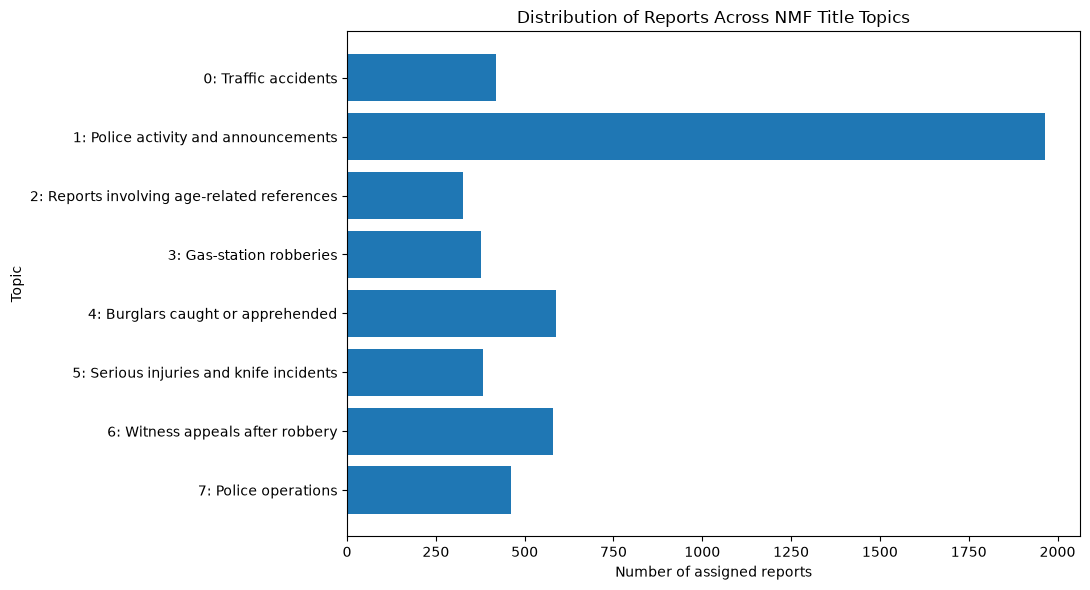

Figure saved: /Users/zaangwenya/Documents/bremen-crime-data-analytics-main/figures/member_02/nmf_titles_topic_distribution.png
Figure exists: True


In [82]:

# Step 5K: Visualise the distribution of assigned reports

import matplotlib.pyplot as plt

topic_counts = (
    final_assignments.loc[
        final_assignments["assignment_status"].eq("assigned")
    ]
    .groupby("topic_id")
    .size()
    .reindex(range(selected_n_topics), fill_value=0)
)

topic_names = [
    f"{topic_id}: {topic_labels[topic_id]}"
    for topic_id in topic_counts.index
]

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(topic_names, topic_counts.values)
ax.set_xlabel("Number of assigned reports")
ax.set_ylabel("Topic")
ax.set_title("Distribution of Reports Across NMF Title Topics")
ax.invert_yaxis()

plt.tight_layout()

figure_path = figures_dir / "nmf_titles_topic_distribution.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", figure_path)
print("Figure exists:", figure_path.exists())

The topic-distribution figure was saved successfully to `figures/member_02/nmf_titles_topic_distribution.png`, and the file-existence check returned `True`. The figure visualises the distribution of assigned reports across the eight topics in the selected NMF model. Based on the assignment counts, Topic 1 has the most reports (1,965), while Topic 2 has the fewest (326).

The figure provides a visual summary of how reports are distributed across the topics, making it easier to identify imbalances than by examining the counts alone. It highlights the dominance of Topic 1 and the smaller size of Topic 2, which may help guide further interpretation and review. Saving the figure also creates a reusable visual for the final report or presentation.

The distribution figure shows the number of reports assigned to each topic, but it does not establish whether the topics are accurate, distinct, or meaningful crime categories. Topic 1's larger size may reflect a broad topic that combines different types of police-related reports. The topic labels and assignments therefore still require qualitative review and comparison with the description-based model.

### 6. Evaluate and compare

Coordinate with Member 6 on the same independent review set for all models. Examine interpretability, label agreement, topic sizes, coverage, and sensitivity to reasonable parameter changes. Explain what the model gets wrong. Do not compare NMF weights with HDBSCAN strengths as if they were the same confidence scale.

In [83]:

# Step 6A: Compare topic sizes and keywords across candidate models

import numpy as np
import pandas as pd

# Only evaluate reports with usable TF-IDF features.
# This prevents zero-feature reports from being assigned to Topic 0.
usable_mask = np.asarray(
    final_tfidf_matrix.getnnz(axis=1)
).ravel() > 0

evaluation_rows = []

for n_topics, model in final_nmf_models.items():
    document_topics = final_nmf_results[n_topics][
        "document_topic_matrix"
    ]

    # Assign each usable report to its highest-scoring topic
    topic_ids = document_topics[usable_mask].argmax(axis=1)

    # Count reports assigned to each topic
    topic_counts = (
        pd.Series(topic_ids)
        .value_counts()
        .reindex(range(n_topics), fill_value=0)
        .sort_index()
    )

    # Get the top five keywords for each topic
    feature_names = final_vectorizer.get_feature_names_out()

    for topic_id, topic_weights in enumerate(model.components_):
        top_indices = topic_weights.argsort()[::-1][:5]
        keywords = ", ".join(feature_names[top_indices])

        evaluation_rows.append({
            "n_topics": n_topics,
            "topic_id": topic_id,
            "n_reports": int(topic_counts.loc[topic_id]),
            "share_of_usable_reports": round(
                int(topic_counts.loc[topic_id]) / int(usable_mask.sum()),
                4
            ),
            "top_keywords": keywords
        })

evaluation_df = pd.DataFrame(evaluation_rows)

print("Usable reports evaluated:", int(usable_mask.sum()))
print("\nTopic size and keyword comparison:")
display(evaluation_df)

print("\nSummary by candidate model:")
display(
    evaluation_df.groupby("n_topics").agg(
        number_of_topics=("topic_id", "count"),
        smallest_topic=("n_reports", "min"),
        largest_topic=("n_reports", "max"),
        mean_topic_size=("n_reports", "mean")
    ).round(2)
)


Usable reports evaluated: 5100

Topic size and keyword comparison:


,n_topics,topic_id,n_reports,share_of_usable_reports,top_keywords
0,6,0,440,0.0863,"accident, traffic, traffic accident, injured t..."
1,6,1,2418,0.4741,"police, bremen, operation, police operation, b..."
2,6,2,370,0.0725,"year, old, year old, missing, old injured"
3,6,3,704,0.1380,"station, gas, gas station, robbery, robbed"
4,6,4,659,0.1292,"burglar, caught, apprehended, burglar caught, ..."
5,6,5,509,0.0998,"injured, seriously injured, seriously, knife, ..."
6,8,0,418,0.0820,"accident, traffic, traffic accident, injured t..."
7,8,1,1965,0.3853,"police, bremen, bremen police, officers, polic..."
8,8,2,326,0.0639,"year, old, year old, missing, old injured"
9,8,3,378,0.0741,"station, gas, gas station, robbed, station robbed"



Summary by candidate model:


,number_of_topics,smallest_topic,largest_topic,mean_topic_size
n_topics,,,,
6,6,370,2418,850.0
8,8,326,1965,637.5
10,10,272,1790,510.0


Across the 6-, 8-, and 10-topic NMF models, several core themes remained consistent, including traffic accidents, police-related reports, age-related references, gas-station robberies, burglar apprehensions, and serious injuries or knife incidents. The 6-topic model grouped a large share of reports into one police-related topic (47.41%). The 8-topic model separated general police activity from police operations and identified a distinct witness-appeal topic. The 10-topic model introduced additional distinctions, including reports about people being robbed, although some witness-appeal and robbery topics appeared to overlap.

Comparing topic sizes and keywords helps assess whether changing the number of topics produces more interpretable and distinct themes. The 8-topic model appears to offer a useful balance between broad coverage and topic separation, making it a reasonable candidate for further evaluation.
 
Topic coherence and separation need to be checked against representative report titles and compared with the description-based model. The additional topics in the 10-topic model may provide useful detail, but some may represent overlapping themes rather than clearly distinct categories. Topic labels are provisional interpretations, not verified crime classifications.

In [84]:

# Step 6B: Inspect representative titles across candidate models


import numpy as np
import pandas as pd

sample_rows = []

# Identify reports with at least one non-zero TF-IDF feature.
usable_mask = np.asarray(
    final_tfidf_matrix.getnnz(axis=1)
).ravel() > 0

# Keep the report rows aligned with the TF-IDF matrix.
usable_reports = model_reports.loc[usable_mask].reset_index(drop=True)

for n_topics, model in final_nmf_models.items():
    document_topic_matrix = final_nmf_results[n_topics][
        "document_topic_matrix"
    ]

    # Keep only reports with usable title features.
    usable_scores = document_topic_matrix[usable_mask]

    # Each report is assigned to the topic with its highest score.
    assigned_topic_ids = usable_scores.argmax(axis=1)

    for topic_id in range(n_topics):

        # Only consider reports actually assigned to this topic.
        topic_positions = np.where(
            assigned_topic_ids == topic_id
        )[0]

        # Rank those reports by their score for this topic.
        ranked_positions = topic_positions[
            np.argsort(
                usable_scores[topic_positions, topic_id]
            )[::-1]
        ][:5]

        for position in ranked_positions:
            sample_rows.append({
                "n_topics": n_topics,
                "topic_id": topic_id,
                "topic_score": round(
                    float(usable_scores[position, topic_id]), 4
                ),
                "report_id": usable_reports.iloc[position]["report_id"],
                "title_en": usable_reports.iloc[position]["title_en"]
            })

representative_titles_df = pd.DataFrame(sample_rows)

display(
    representative_titles_df.sort_values(
        ["n_topics", "topic_id", "topic_score"],
        ascending=[True, True, False]
    ).reset_index(drop=True)
)

,n_topics,topic_id,topic_score,report_id,title_en
0,6,0,0.2434,BR004452,Traffic accident in Strom
1,6,0,0.2434,BR002793,Traffic accident with four involved parties
2,6,0,0.1929,BR002874,Several injured in traffic accident
3,6,0,0.1929,BR004360,Injured after traffic accident
4,6,0,0.1923,BR004571,Several violations after traffic accident
...,...,...,...,...,...
115,10,9,0.3526,BR000821,Man robbed
116,10,9,0.3526,BR003575,Man robbed
117,10,9,0.3526,BR004447,Man robbed
118,10,9,0.3526,BR002298,Man robbed


In [85]:
# Display representative titles for the 8-topic model only

display(
    representative_titles_df[
        representative_titles_df["n_topics"] == 8
    ].sort_values(
        ["topic_id", "topic_score"],
        ascending=[True, False]
    )
)

,n_topics,topic_id,topic_score,report_id,title_en
30,8,0,0.2239,BR002793,Traffic accident with four involved parties
31,8,0,0.2239,BR004452,Traffic accident in Strom
32,8,0,0.1771,BR002874,Several injured in traffic accident
33,8,0,0.1771,BR004360,Injured after traffic accident
34,8,0,0.1769,BR004571,Several violations after traffic accident
35,8,1,0.2833,BR000976,"Wee-woo wee-woo, the police aren't here!"
36,8,1,0.2408,BR005061,Application process starts at the Bremen Police
37,8,1,0.1953,BR003989,Bremen Police accompanies Nordderby
38,8,1,0.1942,BR001371,Police arrests fake police officers
39,8,1,0.1831,BR004051,Bremen Police prepare for the weekend


The representative-title inspection supports the interpretation of several topics from the eight-topic NMF model. Topic 0 contains traffic-accident reports, Topic 3 focuses on gas-station robberies, Topic 4 contains reports about burglars being caught or apprehended, Topic 6 captures witness appeals following robberies, and Topic 7 groups police-operation reports. These examples are consistent with the keywords identified earlier.

Topic 1 contains a broader range of police-related announcements and activities. Topic 5 combines serious injuries and knife-related incidents with some traffic-related injuries. Topic 2 is less specific: its representative titles include missing-person reports, attacks, and robbery or fraud involving people of different ages. The shared age-related wording may contribute to these reports being grouped together, but the topic should not be interpreted as a single crime category.

Some representative titles are repeated across different report IDs. This shows that repeated or similar title wording occurs in the prepared dataset and does not, by itself, establish that the reports are duplicates. The representative titles are useful for interpreting the model, but they do not establish the true category of every report. Topic labels therefore remain proposed interpretations and should be reviewed alongside the description-based model and peer feedback.


In [86]:

#Inspect the metadata files

from pathlib import Path
import json

project_root = Path(
    "/Users/zaangwenya/Documents/bremen-crime-data-analytics-main"
)

template_path = project_root / "templates/member_02/run_metadata.json"
output_path = project_root / "outputs/member_02/run_metadata.json"

for label, path in [
    ("PROJECT TEMPLATE", template_path),
    ("CURRENT OUTPUT METADATA", output_path),
]:
    print(f"\n--- {label} ---")
    print("File exists:", path.exists())

    if path.exists():
        with open(path, "r", encoding="utf-8") as file:
            metadata = json.load(file)

        print(json.dumps(metadata, indent=2))



--- PROJECT TEMPLATE ---
File exists: True
{
  "member_id": "member_02",
  "author": "",
  "reviewer": "",
  "status": "not_started",
  "source_sha256": "05c23babf442967832d277922f2bebe5ebeb43c8891a5e7aafa699644d1a9bf6",
  "base_sha256": "e413c6bcca065480e00084bac8f18e338325803f3f79bf953b4b5f19c88c0534",
  "prepared_sha256": null,
  "report_categories_sha256": null,
  "run_date": null,
  "python_version": "",
  "package_versions": {},
  "methods": [],
  "parameters": {},
  "counts": {},
  "notes": []
}

--- CURRENT OUTPUT METADATA ---
File exists: True
{
  "name": "Assignment 02: Topic modeling using titles",
  "model_id": "nmf_titles",
  "input_files": {
    "prepared_reports": "outputs/member_01/reports_prepared.parquet",
    "sha256": "bf64238b7f929551cf20dadcdd314fa8bf17efe2cd7eab6174fd44dab1a1c139"
  },
  "method": "TF-IDF + Non-negative Matrix Factorization (NMF)",
  "selected_n_topics": 8,
  "method_settings": {
    "vectorizer": "TfidfVectorizer",
    "stop_words": "english",


In [87]:

#verify the project input files

from pathlib import Path
import hashlib
import json
import platform
import importlib.metadata as package_metadata

project_root = Path(
    "/Users/zaangwenya/Documents/bremen-crime-data-analytics-main"
)

template_path = project_root / "templates/member_02/run_metadata.json"

with open(template_path, "r", encoding="utf-8") as file:
    template = json.load(file)

print("TEMPLATE CHECKSUMS")
for key in [
    "source_sha256",
    "base_sha256",
    "prepared_sha256",
    "report_categories_sha256",
]:
    print(f"{key}: {template.get(key)}")

print("\nPOSSIBLE INPUT FILES")
for path in sorted(project_root.rglob("*")):
    if not path.is_file():
        continue
    if any(part.startswith(".") for part in path.relative_to(project_root).parts):
        continue

    name = path.name.lower()
    if any(word in name for word in [
        "report", "crime", "categor", "source", "base"
    ]) and path.suffix.lower() in [
        ".csv", ".parquet", ".json", ".xlsx", ".xls"
    ]:
        print(path.relative_to(project_root))

print("\nPACKAGE VERSIONS")
print("Python:", platform.python_version())

for package in ["pandas", "numpy", "scikit-learn", "pyarrow"]:
    try:
        print(f"{package}: {package_metadata.version(package)}")
    except package_metadata.PackageNotFoundError:
        print(f"{package}: not installed")


TEMPLATE CHECKSUMS
source_sha256: 05c23babf442967832d277922f2bebe5ebeb43c8891a5e7aafa699644d1a9bf6
base_sha256: e413c6bcca065480e00084bac8f18e338325803f3f79bf953b4b5f19c88c0534
prepared_sha256: None
report_categories_sha256: None

POSSIBLE INPUT FILES
bremen_crime_data_2026.parquet
outputs/member_01/reports_prepared.parquet
outputs/member_06/source_checks.csv
shared/reports_base.parquet
shared/source_manifest.json
templates/member_01/district_category_counts.csv
templates/member_01/highest_district_by_category.csv
templates/member_06/category_codebook.csv
templates/member_06/category_mapping.csv
templates/member_06/category_overrides.csv
templates/member_06/report_categories.csv

PACKAGE VERSIONS
Python: 3.11.13
pandas: 3.1.0
numpy: 2.4.6
scikit-learn: 1.9.1
pyarrow: 26.0.0


In [88]:
#checksum verification cell

from pathlib import Path
import hashlib

project_root = Path(
    "/Users/zaangwenya/Documents/bremen-crime-data-analytics-main"
)

files_to_check = {
    "source": project_root / "bremen_crime_data_2026.parquet",
    "base": project_root / "shared/reports_base.parquet",
    "prepared": project_root / "outputs/member_01/reports_prepared.parquet",
    "report_categories": project_root / "templates/member_06/report_categories.csv",
}

for name, path in files_to_check.items():
    if not path.exists():
        print(f"{name}: FILE NOT FOUND — {path}")
        continue

    sha256 = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha256.update(chunk)

    print(f"{name}_sha256: {sha256.hexdigest()}")


source_sha256: 05c23babf442967832d277922f2bebe5ebeb43c8891a5e7aafa699644d1a9bf6
base_sha256: e413c6bcca065480e00084bac8f18e338325803f3f79bf953b4b5f19c88c0534
prepared_sha256: bf64238b7f929551cf20dadcdd314fa8bf17efe2cd7eab6174fd44dab1a1c139
report_categories_sha256: 27734ab5622e39a2de2b057e9a9756bbe3493de3d0d20f35d346a852a3aad9f1


In [89]:

from pathlib import Path
import json

project_root = Path(
    "/Users/zaangwenya/Documents/bremen-crime-data-analytics-main"
)

template_path = project_root / "templates/member_02/run_metadata.json"
output_path = project_root / "outputs/member_02/run_metadata.json"

with open(template_path, "r", encoding="utf-8") as file:
    metadata = json.load(file)

with open(output_path, "r", encoding="utf-8") as file:
    previous = json.load(file)

# Keep the common project metadata structure and verified checksums.
metadata.update({
    "member_id": "member_02",
    "author": "Zanele",
    "reviewer": "",
    "status": "in_progress",
    "source_sha256": (
        "05c23babf442967832d277922f2bebe5ebeb43c8891a5e7aafa699644d1a9bf6"
    ),
    "base_sha256": (
        "e413c6bcca065480e00084bac8f18e338325803f3f79bf953b4b5f19c88c0534"
    ),
    "prepared_sha256": (
        "bf64238b7f929551cf20dadcdd314fa8bf17efe2cd7eab6174fd44dab1a1c139"
    ),
    "report_categories_sha256": (
        "27734ab5622e39a2de2b057e9a9756bbe3493de3d0d20f35d346a852a3aad9f1"
    ),
    "run_date": previous.get("run_date"),
    "python_version": previous.get(
        "package_versions", {}
    ).get("python", ""),
    "package_versions": {
        "pandas": "3.1.0",
        "numpy": "2.4.6",
        "scikit-learn": "1.9.1",
        "pyarrow": "26.0.0"
    },
    "methods": [
        "TF-IDF vectorization of prepared English report titles",
        "Non-negative Matrix Factorization (NMF)",
        "Candidate topic counts compared: 6, 8, and 10",
        "Selected candidate: 8 topics",
        "Reports with zero TF-IDF features remain unassigned"
    ],
    "parameters": previous.get("method_settings", {}),
    "counts": {
        "prepared_reports": 5126,
        "eligible_reports": 5124,
        "usable_tfidf_reports": 5100,
        "unique_assignment_report_ids": 5126,
        "assigned": 5100,
        "unassigned": 24,
        "excluded": 2,
        "missing_text": 0,
        "invalid_embedding": 0,
        "topics": 8,
        "representative_samples": 40
    },
    "notes": [
        "Topic labels are proposed interpretations, not verified crime categories.",
        "NMF topic scores are not calibrated probabilities.",
        "The two excluded reports are retained in the assignment output.",
        "Peer review and comparison with the description-based model remain pending."
    ]
})

# Preserve additional run details already recorded by the notebook.
for key in ["name", "model_id", "input_files", "method",
            "method_settings", "candidate_model_results"]:
    if key in previous:
        metadata[key] = previous[key]

with open(output_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2, ensure_ascii=False)
    file.write("\n")

print("Updated:", output_path.relative_to(project_root))
print("Status:", metadata["status"])
print("Prepared checksum:", metadata["prepared_sha256"])
print("Counts:", metadata["counts"])


Updated: outputs/member_02/run_metadata.json
Status: in_progress
Prepared checksum: bf64238b7f929551cf20dadcdd314fa8bf17efe2cd7eab6174fd44dab1a1c139
Counts: {'prepared_reports': 5126, 'eligible_reports': 5124, 'usable_tfidf_reports': 5100, 'unique_assignment_report_ids': 5126, 'assigned': 5100, 'unassigned': 24, 'excluded': 2, 'missing_text': 0, 'invalid_embedding': 0, 'topics': 8, 'representative_samples': 40}


In [ ]:
#Final output validation

from pathlib import Path
import hashlib
import json
import pandas as pd

project_root = Path.cwd().parent
output_dir = project_root / "outputs" / "member_02"
prepared_file = (
    project_root / "outputs" / "member_01" / "reports_prepared.parquet"
)
figure_file = (
    project_root / "figures" / "member_02"
    / "nmf_titles_topic_distribution.png"
)

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

required_files = [
    "nmf_titles_assignments.csv",
    "nmf_titles_topics.csv",
    "nmf_titles_samples.csv",
    "nmf_titles_run.csv",
    "run_metadata.json",
    "handover.md",
]

for name in required_files:
    path = output_dir / name
    assert path.is_file() and path.stat().st_size > 0, (
        f"Missing or empty file: {name}"
    )

assignments = pd.read_csv(
    output_dir / "nmf_titles_assignments.csv",
    keep_default_na=False
)
topics = pd.read_csv(output_dir / "nmf_titles_topics.csv")
samples = pd.read_csv(
    output_dir / "nmf_titles_samples.csv",
    keep_default_na=False
)
run = pd.read_csv(output_dir / "nmf_titles_run.csv")

with open(output_dir / "run_metadata.json", encoding="utf-8") as f:
    metadata = json.load(f)

assert len(assignments) == 5126
assert assignments["report_id"].nunique() == 5126
assert assignments["assignment_status"].value_counts().to_dict() == {
    "assigned": 5100,
    "unassigned": 24,
    "excluded": 2,
}
assert len(topics) == 8
assert len(samples) == 40
assert len(run) == 1

assert metadata["prepared_sha256"] == sha256_file(prepared_file)
assert metadata["status"] == "in_progress"
assert metadata["reviewer"] == ""

assert figure_file.is_file() and figure_file.stat().st_size > 0

print("FINAL VALIDATION PASSED")
print("Assignments:", len(assignments))
print("Topics:", len(topics))
print("Representative samples:", len(samples))
print("Prepared checksum matches.")
print("Figure exists.")
print("Peer review remains pending.")

FINAL VALIDATION PASSED
Assignments: 5126
Topics: 8
Representative samples: 40
Prepared checksum matches.
Figure exists.
Peer review remains pending.


### 7. Export a complete candidate handover

Save the four nmf_titles CSVs listed below, run_metadata.json and handover.md. Include a keyword chart or topic-size chart, representative examples and short interpretations. Record prepared-input checksum, versions, random seed, vectorizer settings, selected topic count, elapsed time and warnings. Keep code that recreates the run.

The final eight-topic NMF model grouped eligible crime reports into themes based on recurring words and phrases in their titles. A total of 5,100 reports were assigned to topics, while 24 eligible reports remained unassigned because their titles contained no usable TF-IDF features. The two excluded reports were retained with their appropriate status, preserving all 5,126 report IDs.

The topics cover themes such as traffic accidents, police activity, gas-station robberies, burglar apprehensions, serious injuries, witness appeals and police operations. The saved output files and run metadata support reproducibility and allow the results to be inspected and compared with the description-based model.

However, some topics overlap or combine different types of reports, meaning their labels should be treated as proposed interpretations rather than confirmed crime categories. The eight-topic model still needs to be compared with the description-based model and reviewed by a peer before final conclusions are established.

## What you must submit to the main workstation

Submit this completed notebook with saved outputs, your files in outputs/member_02, and figures in figures/member_02. Run the notebook top-to-bottom before submission. Do not submit empty templates as results.

- **nmf_titles_assignments.csv** = columns: `report_id`, `model_id`, `topic_id`, `assignment_status`.
- **nmf_titles_topics.csv** = columns: `model_id`, `topic_id`, `keywords`, `n_reports`, `proposed_category`, `notes`.
- **nmf_titles_samples.csv** = columns: `model_id`, `topic_id`, `report_id`, `selection_reason`.
- **nmf_titles_run.csv** = columns: `model_id`, `n_topics`, `assigned_reports`, `unassigned_reports`, `excluded_reports`, `missing_text_reports`, `invalid_embedding_reports`, `elapsed_seconds`, `parameters`.
- **run_metadata.json** = name, input checksums, package versions, method settings, run date, record counts and status.
- **handover.md** = what you did, results, limitations, reviewer comments, output inventory and outstanding questions.

**Main notebook destination:** Topic modeling: titles; Model comparison and approved labels.

Member 6 needs assignments, topic descriptions and example IDs. Use the shared output schemas, not a custom column naming scheme. Share model mistakes with the group as well as successful examples.
### Output conventions

- Keep report_id as the original BR string. Topic IDs are integers within a model, or empty for missing/excluded inputs; HDBSCAN noise is -1.
- For model tables, use the exact model_id and assignment_status values: assigned, unassigned, excluded, missing_text, invalid_embedding. Keywords can be semicolon-separated text. n_reports is the number of reports represented by that topic/status, not a score.
- Store shares/agreement rates as fractions from 0 to 1; multiply by 100 only when displaying percentages. Record which report set is the denominator. A model weight is not a calibrated category probability.
- Date keys use YYYY-MM-DD; monthly keys use YYYY-MM. Keep literal text labels intact when reading lookup CSVs (keep_default_na=False can preserve the original text None).
- Copy templates/member_XX/run_metadata.json into your output folder only when filling it with an actual run. Keep the common metadata keys, replace placeholders, and mark submitted/reviewed only when true. Record SHA-256 file versions, not just filenames.
- Final category statuses are mapped_topic/manual_override/unclear/unassigned/excluded/missing_text/invalid_embedding. Elderly review statuses are yes/no_evidence/unclear/not_reviewed/excluded. Unclear and unreviewed are not negative results.

### Final submission checks

- [ ] All expected output files are populated, or a genuine empty result is explained (for example, no anomalies met the rule).
- [ ] Every report-level table uses report_id and includes the required cohort, without unexpected duplicates.
- [ ] IDs, source/prepared checksums, categories and denominators match the shared contract.
- [ ] Required charts have descriptive titles, labels, units, periods and readable text; export PNG/HTML as appropriate.
- [ ] Code runs in order; results and explanations agree; raw/debug output is bounded.
- [ ] A peer reviewer has checked the method, sample reports, files and conclusions.
- [ ] handover.md says exactly what to import into the main notebook and lists anything still unresolved.

### Your handover summary

**What I completed:** ______  
**Most useful finding (after execution):** ______  
**Output files and row counts:** ______  
**Main limitations:** ______  
**Reviewer decision:** ______  
**Next person who needs my outputs:** ______


**What I completed:** 
Fitted TF-IDF and NMF models with 6, 8 and 10 topics using Member 01's prepared dataset. Selected the eight-topic model as a candidate, inspected keywords and representative titles, generated the required output files and topic-distribution figure, and validated the saved assignments.

**Most useful finding (after execution):** 
The eight-topic model identified recurring themes in traffic accidents, gas-station robberies, burglar apprehensions, witness appeals and police operations. Some topics, particularly those involving police activity and age-related references, were broader and require further review.

**Output files and row counts:** 
`nmf_titles_assignments.csv` — 5,126 rows; `nmf_titles_topics.csv` — 8 rows; `nmf_titles_samples.csv` — 40 rows; `nmf_titles_run.csv` — 1 row; `run_metadata.json` and `handover.md` — generated. Topic-distribution figure saved under `figures/member_02/`.

**Main limitations:** 
Twenty-four eligible reports had zero TF-IDF features and remained unassigned. NMF scores are not calibrated probabilities, and topic labels are proposed interpretations rather than confirmed crime categories. Some topics overlap or combine different report types.

**Reviewer decision:** 
Pending comparison with Member 03's description-based model and review by Member 06.

**Next person who needs my outputs:** 
Member 03 for model comparison and Member 06 for peer review and coordination of the final category decisions.